In [1]:
# Dependencias y utilidades usadas en todo el notebook
from collections import Counter
import csv
import hashlib
import json
import re
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.cluster import MiniBatchKMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
)
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ParameterGrid, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder


# EDA y limpieza: vehículos involucrados en siniestros viales

Este notebook carga el CSV oficial, revisa su calidad, genera una EDA rápida y exporta `vehiculos_accidentes_limpio.csv`. La unidad de observación es un **vehículo involucrado**, no necesariamente un accidente único.

In [2]:
BASE = Path('.')
RAW = BASE / 'VEHICULOS_INVOLUCRADOS_EN_UN_ACCIDENTE_DE_TRANSITO_LEY_2251-2022_20261028.csv'
CLEAN = BASE / 'vehiculos_accidentes_limpio.csv'
text_cols = ['MARCA_VEHICULO', 'TIPO_VEHICULO', 'GRAVEDAD_ACCIDENTE',
             'DEPARTAMENTO_ACCIDENTE', 'MUNICIPIO_ACCIDENTE', 'AUTORIDAD_DE_TRANSITO']

def clean_int(value):
    digits = re.sub(r'[^0-9]', '', (value or '').strip())
    return int(digits) if digits else None


In [3]:
# Carga, normalización, trazabilidad y exportación reproducible
with RAW.open(encoding='utf-8-sig', newline='') as f:
    reader = csv.DictReader(f)
    raw_fieldnames = reader.fieldnames or []

accident_id_candidates = [
    name for name in raw_fieldnames
    if name and (
        name.upper() in {'ID_ACCIDENTE', 'ACCIDENTE_ID', 'NUMERO_ACCIDENTE'}
        or 'ID_ACCIDENTE' in name.upper()
    )
]
ACCIDENT_ID_COLUMN = accident_id_candidates[0] if accident_id_candidates else None
SOURCE_DATASET = "RUNT / datos.gov.co: 6jmc-vaxk"

base_fields = [
    'MARCA_VEHICULO','MODELO_VEHICULO','TIPO_VEHICULO','EDAD_VEHICULO',
    'FECHA_ACCIDENTE','GRAVEDAD_ACCIDENTE','DEPARTAMENTO_ACCIDENTE',
    'MUNICIPIO_ACCIDENTE','AUTORIDAD_DE_TRANSITO'
]
fields = [
    'REGISTRO_ID', 'ACCIDENTE_ID', 'ACCIDENTE_ID_TIPO',
    *base_fields,
    'ANIO_ACCIDENTE', 'MES_ACCIDENTE', 'EDAD_VEHICULO_LIMPIA'
]
rows, missing_before, invalid_model_year, invalid_month = [], Counter(), 0, 0
official_ids, missing_official_ids = set(), 0

with RAW.open(encoding='utf-8-sig', newline='') as f:
    for row_number, raw in enumerate(csv.DictReader(f), start=1):
        r = {k: (v or '').strip() for k, v in raw.items()}
        for k in text_cols:
            r[k] = re.sub(r'\s+', ' ', r[k]).upper()
        for k, v in r.items():
            if not v:
                missing_before[k] += 1

        model = clean_int(r['MODELO_VEHICULO'])
        raw_age = clean_int(r['EDAD_VEHICULO'])
        age = raw_age
        month, year = (
            r['FECHA_ACCIDENTE'].split('/')
            if '/' in r['FECHA_ACCIDENTE'] else ('', '')
        )
        month_i, year_i = clean_int(month), clean_int(year)
        if month_i is not None and not 1 <= month_i <= 12:
            invalid_month += 1
            month_i = None

        # En Colombia es normal que un vehículo se venda como modelo del año siguiente.
        valid_model = model is not None and 1900 <= model <= 2027
        if model is not None and not valid_model:
            invalid_model_year += 1
        model_i = model if valid_model else None
        if age is not None and not 0 <= age <= 100:
            age = None
        if age is None and model_i is not None and year_i is not None and model_i <= year_i:
            age = year_i - model_i

        # El hash identifica de forma estable el registro, no inventa un accidente.
        hash_payload = '\x1f'.join(
            [str(row_number)] + [f'{k}={r.get(k, "")}' for k in raw_fieldnames]
        )
        registro_id = 'REG-' + hashlib.sha1(
            hash_payload.encode('utf-8')
        ).hexdigest()[:16]
        official_id = (
            re.sub(r'\s+', ' ', r.get(ACCIDENT_ID_COLUMN, '')).strip()
            if ACCIDENT_ID_COLUMN else ''
        )
        if official_id:
            official_ids.add(official_id)
        else:
            missing_official_ids += 1

        output_row = {
            'REGISTRO_ID': registro_id,
            # Si no existe ID oficial, el valor es un surrogate de fila y no se
            # utilizará para afirmar que dos vehículos pertenecen al mismo accidente.
            'ACCIDENTE_ID': official_id or registro_id,
            'ACCIDENTE_ID_TIPO': 'oficial' if official_id else 'surrogate_registro',
            **r,
            'MODELO_VEHICULO': model_i or '',
            'EDAD_VEHICULO': (
                raw_age if raw_age is not None and 0 <= raw_age <= 100 else ''
            ),
            'FECHA_ACCIDENTE': (
                f'{month_i:02d}/{year_i}' if month_i and year_i else ''
            ),
            'ANIO_ACCIDENTE': year_i or '',
            'MES_ACCIDENTE': month_i or '',
            'EDAD_VEHICULO_LIMPIA': age if age is not None else '',
        }
        rows.append(output_row)

official_id_complete = (
    ACCIDENT_ID_COLUMN is not None
    and missing_official_ids == 0
    and len(official_ids) > 0
)
ACCIDENT_ID_AVAILABLE = official_id_complete
if not ACCIDENT_ID_AVAILABLE:
    print(
        'Advertencia: la fuente no contiene un identificador oficial de accidente '
        'completo. ACCIDENTE_ID se conserva como surrogate por registro y no se '
        'usará para agrupar vehículos.'
    )

with CLEAN.open('w', encoding='utf-8', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=fields)
    writer.writeheader()
    writer.writerows(rows)

print(f'Registros: {len(rows):,}')
print('Fuente:', SOURCE_DATASET)
print('Faltantes originales:', dict(missing_before))
print('Modelos fuera del rango plausible tratados como faltantes:', f'{invalid_model_year:,}')
print('Fechas con mes inválido:', f'{invalid_month:,}')
print('IDs oficiales distintos:', f'{len(official_ids):,}')
print('Registros sin ID oficial:', f'{missing_official_ids:,}')
print('Tipo de ACCIDENTE_ID:', 'oficial' if ACCIDENT_ID_AVAILABLE else 'surrogate_registro')


Advertencia: la fuente no contiene un identificador oficial de accidente completo. ACCIDENTE_ID se conserva como surrogate por registro y no se usará para agrupar vehículos.


Registros: 450,335
Fuente: RUNT / datos.gov.co: 6jmc-vaxk
Faltantes originales: {'EDAD_VEHICULO': 20}
Modelos fuera del rango plausible tratados como faltantes: 0
Fechas con mes inválido: 0
IDs oficiales distintos: 0
Registros sin ID oficial: 450,335
Tipo de ACCIDENTE_ID: surrogate_registro


In [4]:
def top(column, n=10):
    return Counter(r[column] for r in rows if r[column]).most_common(n)

for col in ['GRAVEDAD_ACCIDENTE', 'TIPO_VEHICULO', 'DEPARTAMENTO_ACCIDENTE', 'ANIO_ACCIDENTE']:
    print(f'\n{col}')
    for value, count in top(col): print(f'{value}: {count:,}')

target = Counter(r['GRAVEDAD_ACCIDENTE'] for r in rows)
total = sum(target.values())
print('\nDistribución del objetivo:', {k: f'{v/total:.2%}' for k, v in target.items()})
print('Edad limpia faltante:', sum(not r['EDAD_VEHICULO_LIMPIA'] for r in rows))



GRAVEDAD_ACCIDENTE

CON HERIDOS: 426,436
CON MUERTOS: 23,899

TIPO_VEHICULO


MOTOCICLETA: 255,266
AUTOMOVIL: 99,900
CAMIONETA: 38,438
BUS: 17,439
CAMION: 12,274
CAMPERO: 9,691
TRACTOCAMION: 5,797
MICROBUS: 4,813
BUSETA: 3,168
VOLQUETA: 2,221

DEPARTAMENTO_ACCIDENTE


ANTIOQUIA: 175,618
BOGOTA D.C.: 62,990
VALLE DEL CAUCA: 56,503
SANTANDER: 19,595
ATLANTICO: 14,997
CUNDINAMARCA: 13,845
TOLIMA: 12,808
RISARALDA: 12,568
BOLIVAR: 10,410
CALDAS: 9,962

ANIO_ACCIDENTE
2024: 121,050
2022: 115,201
2023: 111,898
2025: 66,891
2026: 35,295

Distribución del objetivo: {'CON HERIDOS': '94.69%', 'CON MUERTOS': '5.31%'}


Edad limpia faltante: 854


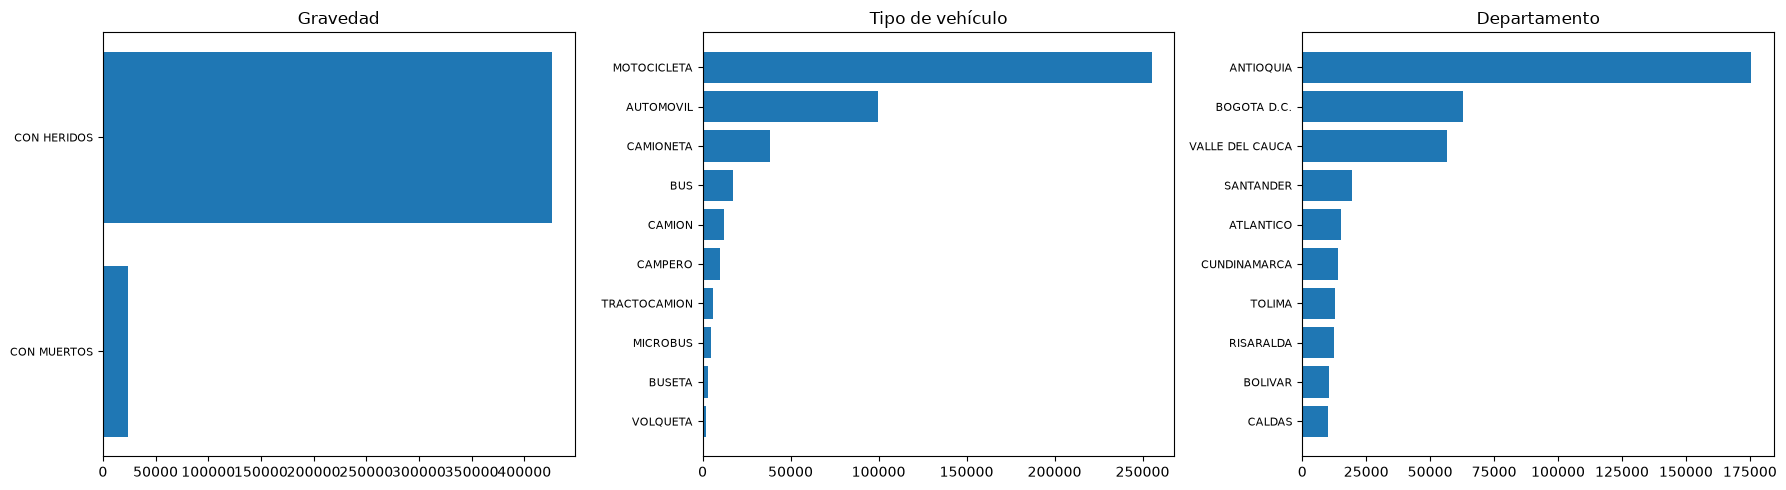

In [5]:
# Visualizaciones simples, sin asumir que una fila equivale a un accidente
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (title, values) in zip(axes, [
    ('Gravedad', top('GRAVEDAD_ACCIDENTE', 5)),
    ('Tipo de vehículo', top('TIPO_VEHICULO', 10)),
    ('Departamento', top('DEPARTAMENTO_ACCIDENTE', 10))]):
    labels, counts = zip(*values)
    ax.barh(list(labels)[::-1], list(counts)[::-1])
    ax.set_title(title); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout()
plt.show()


## Modelado supervisado: unidad, objetivo y diseño

La fuente oficial publicada por RUNT contiene vehículos involucrados, pero el CSV
actual no trae un identificador de siniestro. El notebook conserva siempre
`ACCIDENTE_ID`: es oficial cuando la fuente lo entrega y, en caso contrario, es un
surrogate único de registro marcado como `surrogate_registro`. Nunca se usa ese
surrogate para agrupar vehículos.

Cuando exista un ID oficial completo, el pipeline agrega vehículos a nivel accidente,
valida que los accidentes no se repitan entre particiones y modela la gravedad del
siniestro. Mientras el ID oficial no exista, la unidad queda explícitamente como
registro de vehículo y el score significa gravedad reportada condicionada a un
registro observado, no probabilidad de ocurrencia de accidente.


## Preparación de datos para modelado

Se cargan las variables limpias, se convierten los campos numéricos y se crean variables derivadas sin utilizar la etiqueta. La separación temporal reserva 2026 como prueba final.

In [6]:
"""Modelado supervisado y clustering para accidentes viales.

La unidad de análisis es accidente cuando existe ACCIDENTE_ID oficial completo;
de lo contrario, es registro de vehículo. Un surrogate de fila no se interpreta
como un identificador de accidente.
"""

BASE = Path.cwd()
DATA = BASE / "vehiculos_accidentes_limpio.csv"

if not DATA.exists():
    raise FileNotFoundError(f"No se encontró el dataset limpio: {DATA}")

df = pd.read_csv(DATA)
df["ANIO_ACCIDENTE"] = pd.to_numeric(df["ANIO_ACCIDENTE"], errors="coerce")
df["MES_ACCIDENTE"] = pd.to_numeric(df["MES_ACCIDENTE"], errors="coerce")
df["MODELO_VEHICULO"] = pd.to_numeric(df["MODELO_VEHICULO"], errors="coerce")
df["EDAD_VEHICULO_LIMPIA"] = pd.to_numeric(
    df["EDAD_VEHICULO_LIMPIA"], errors="coerce"
)
df["y"] = (df["GRAVEDAD_ACCIDENTE"] == "CON MUERTOS").astype(int)
if "ACCIDENTE_ID" not in df.columns or "ACCIDENTE_ID_TIPO" not in df.columns:
    raise ValueError(
        "El CSV limpio debe incluir ACCIDENTE_ID y ACCIDENTE_ID_TIPO. "
        "Vuelve a ejecutar la celda de limpieza."
    )

ACCIDENT_ID_AVAILABLE = (
    df["ACCIDENTE_ID_TIPO"].eq("oficial").all()
    and df["ACCIDENTE_ID"].notna().all()
    and df["ACCIDENTE_ID"].nunique() > 0
)
if ACCIDENT_ID_AVAILABLE:
    print(f"Accidentes oficiales identificados: {df['ACCIDENTE_ID'].nunique():,}")
else:
    print(
        "No hay ID oficial completo: se conserva la unidad de registro de vehículo "
        "y se evita la agregación artificial."
    )


def join_values(series, limit=8):
    values = sorted({str(value) for value in series.dropna() if str(value).strip()})
    return "|".join(values[:limit]) if values else "SIN_DATO"


def aggregate_accidents(vehicle_df):
    grouped = vehicle_df.groupby("ACCIDENTE_ID", as_index=False, dropna=False)
    accident_df = grouped.agg(
        REGISTRO_ID=("REGISTRO_ID", "first"),
        ACCIDENTE_ID_TIPO=("ACCIDENTE_ID_TIPO", "first"),
        MARCA_VEHICULO=("MARCA_VEHICULO", join_values),
        MODELO_VEHICULO=("MODELO_VEHICULO", "median"),
        TIPO_VEHICULO=("TIPO_VEHICULO", join_values),
        EDAD_VEHICULO_LIMPIA=("EDAD_VEHICULO_LIMPIA", "median"),
        FECHA_ACCIDENTE=("FECHA_ACCIDENTE", "first"),
        ANIO_ACCIDENTE=("ANIO_ACCIDENTE", "first"),
        MES_ACCIDENTE=("MES_ACCIDENTE", "first"),
        DEPARTAMENTO_ACCIDENTE=("DEPARTAMENTO_ACCIDENTE", "first"),
        MUNICIPIO_ACCIDENTE=("MUNICIPIO_ACCIDENTE", "first"),
        AUTORIDAD_DE_TRANSITO=("AUTORIDAD_DE_TRANSITO", "first"),
        y=("y", "max"),
        NUM_VEHICULOS=("REGISTRO_ID", "nunique"),
        NUM_TIPOS_VEHICULO=("TIPO_VEHICULO", "nunique"),
        NUM_MOTOS=(
            "TIPO_VEHICULO",
            lambda values: int((values == "MOTOCICLETA").sum()),
        ),
        NUM_PESADOS=(
            "TIPO_VEHICULO",
            lambda values: int(values.isin(
                ["CAMION", "TRACTOCAMION", "VOLQUETA", "BUS", "MICROBUS", "BUSETA"]
            ).sum()),
        ),
    )
    accident_df["GRAVEDAD_ACCIDENTE"] = np.where(
        accident_df["y"].eq(1), "CON MUERTOS", "CON HERIDOS"
    )
    return accident_df


analysis_df = (
    aggregate_accidents(df) if ACCIDENT_ID_AVAILABLE else df.copy()
)
if not ACCIDENT_ID_AVAILABLE:
    analysis_df["NUM_VEHICULOS"] = 1
    analysis_df["NUM_TIPOS_VEHICULO"] = 1
    analysis_df["NUM_MOTOS"] = (
        analysis_df["TIPO_VEHICULO"] == "MOTOCICLETA"
    ).astype(int)
    analysis_df["NUM_PESADOS"] = analysis_df["TIPO_VEHICULO"].isin(
        ["CAMION", "TRACTOCAMION", "VOLQUETA", "BUS", "MICROBUS", "BUSETA"]
    ).astype(int)

analysis_df["ANTIGUEDAD_REPORTADA"] = analysis_df[
    "EDAD_VEHICULO_LIMPIA"
].clip(0, 100)
analysis_df["MODELO_ADELANTADO"] = (
    analysis_df["MODELO_VEHICULO"] > analysis_df["ANIO_ACCIDENTE"]
).astype(int)
analysis_df["VEHICULO_NUEVO"] = (
    analysis_df["ANTIGUEDAD_REPORTADA"] <= 2
).astype(int)
analysis_df["TIPO_DEPARTAMENTO"] = (
    analysis_df["TIPO_VEHICULO"].fillna("SIN_DATO")
    + "__"
    + analysis_df["DEPARTAMENTO_ACCIDENTE"].fillna("SIN_DATO")
)

categorical = [
    "MARCA_VEHICULO",
    "TIPO_VEHICULO",
    "DEPARTAMENTO_ACCIDENTE",
    "MUNICIPIO_ACCIDENTE",
    "AUTORIDAD_DE_TRANSITO",
    "TIPO_DEPARTAMENTO",
]
categorical_base = categorical[:-1]
numeric = [
    "MODELO_VEHICULO",
    "ANTIGUEDAD_REPORTADA",
    "ANIO_ACCIDENTE",
    "MES_ACCIDENTE",
    "MODELO_ADELANTADO",
    "VEHICULO_NUEVO",
    "NUM_VEHICULOS",
    "NUM_TIPOS_VEHICULO",
    "NUM_MOTOS",
    "NUM_PESADOS",
]

# 2026 permanece como prueba final. En presencia de IDs oficiales se valida
# además que los grupos de accidente sean disjuntos entre particiones.
train = analysis_df[analysis_df["ANIO_ACCIDENTE"] <= 2024].copy()
valid = analysis_df[analysis_df["ANIO_ACCIDENTE"] == 2025].copy()
test = analysis_df[analysis_df["ANIO_ACCIDENTE"] == 2026].copy()
if train.empty or valid.empty or test.empty:
    raise ValueError(
        "La separación temporal requiere registros en entrenamiento, "
        "validación y prueba (<=2024, 2025 y 2026)."
    )
if train["y"].nunique() < 2:
    raise ValueError("El entrenamiento debe contener ambas clases de gravedad.")
if ACCIDENT_ID_AVAILABLE:
    partition_sets = {
        "train": set(train["ACCIDENTE_ID"]),
        "valid": set(valid["ACCIDENTE_ID"]),
        "test": set(test["ACCIDENTE_ID"]),
    }
    for left, right in (("train", "valid"), ("train", "test"), ("valid", "test")):
        overlap = partition_sets[left] & partition_sets[right]
        if overlap:
            raise ValueError(
                f"Fuga de accidentes entre {left} y {right}: {len(overlap):,} IDs."
            )


No hay ID oficial completo: se conserva la unidad de registro de vehículo y se evita la agregación artificial.


## Preprocesamiento dentro del pipeline

Las variables categóricas se imputan con la moda y se codifican según la familia de
modelo: one-hot para los modelos lineales y el bosque, y *target encoding* (con
validación cruzada interna de scikit-learn) para el gradient boosting, que maneja
mejor la alta cardinalidad de municipios y marcas. Las numéricas se imputan con la
mediana. Todo el preprocesamiento se ajusta dentro de cada pipeline para evitar
fuga de información.

In [7]:
def make_preprocess(columns):
    """One-hot + imputación: entrada estándar para los modelos lineales y el bosque."""
    return ColumnTransformer(
        [
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    (
                        "onehot",
                        OneHotEncoder(
                            handle_unknown="ignore",
                            min_frequency=10,
                            dtype=np.float32,
                        ),
                    ),
                ]),
                columns,
            ),
            (
                "num",
                Pipeline([("imputer", SimpleImputer(strategy="median"))]),
                numeric,
            ),
        ],
        remainder="drop",
    )


def make_target_preprocess(columns):
    """Target encoding con CV interna: apto para categóricas de alta cardinalidad."""
    return ColumnTransformer(
        [
            (
                "cat",
                Pipeline([
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("target", TargetEncoder(target_type="binary", random_state=42)),
                ]),
                columns,
            ),
            (
                "num",
                Pipeline([("imputer", SimpleImputer(strategy="median"))]),
                numeric,
            ),
        ],
        remainder="drop",
    )


## Benchmark y particiones

Se comparan tres familias con roles distintos: la regresión logística como referencia
interpretable, un `RandomForestClassifier` como benchmark no lineal clásico y un
`HistGradientBoostingClassifier` (boosting de histogramas nativo de scikit-learn)
como candidato de mayor capacidad, acompañado de *target encoding* para las
categóricas de alta cardinalidad. Los hiperparámetros de todas las familias se
buscan con cortes temporales históricos, ajustando regularización, peso de la clase
minoritaria y complejidad de los árboles. La prueba 2026 no participa en el tuning
ni en la selección.


In [8]:
def make_logistic(columns, C, class_weight):
    return Pipeline(
        [
            ("preprocess", make_preprocess(columns)),
            (
                "model",
                LogisticRegression(
                    class_weight=class_weight,
                    C=C,
                    max_iter=300,
                    solver="liblinear",
                    random_state=42,
                ),
            ),
        ]
    )


def make_random_forest(params):
    return Pipeline(
        [
            ("preprocess", make_preprocess(categorical)),
            (
                "model",
                RandomForestClassifier(
                    n_estimators=params["n_estimators"],
                    max_depth=params["max_depth"],
                    min_samples_leaf=params["min_samples_leaf"],
                    max_features=params["max_features"],
                    class_weight=params["class_weight"],
                    n_jobs=-1,
                    random_state=42,
                ),
            ),
        ]
    )


def make_gradient_boosting(params):
    return Pipeline(
        [
            ("preprocess", make_target_preprocess(categorical)),
            (
                "model",
                HistGradientBoostingClassifier(
                    learning_rate=params["learning_rate"],
                    max_iter=params["max_iter"],
                    max_leaf_nodes=params["max_leaf_nodes"],
                    min_samples_leaf=params["min_samples_leaf"],
                    l2_regularization=params["l2_regularization"],
                    class_weight=params["class_weight"],
                    early_stopping=True,
                    validation_fraction=0.1,
                    random_state=42,
                ),
            ),
        ]
    )


candidate_specs = []
for family, columns in (
    ("logistica_base", categorical_base),
    ("logistica_interacciones", categorical),
):
    for params in ParameterGrid({
        "C": [0.1, 0.5, 2.0],
        "class_weight": ["balanced", {0: 1, 1: 5}],
    }):
        candidate_specs.append({
            "familia": family,
            "nombre": (
                f"{family}_C{params['C']}_"
                f"{'balanced' if params['class_weight'] == 'balanced' else 'peso5'}"
            ),
            "params": params,
            "model": lambda p=params, cols=columns: make_logistic(
                cols, p["C"], p["class_weight"]
            ),
        })

for params in ParameterGrid({
    "n_estimators": [80],
    "max_depth": [12, 18],
    "min_samples_leaf": [20],
    "max_features": ["sqrt"],
    "class_weight": ["balanced"],
}):
    candidate_specs.append({
        "familia": "random_forest",
        "nombre": (
            f"random_forest_depth{params['max_depth']}_"
            f"leaf{params['min_samples_leaf']}"
        ),
        "params": params,
        "model": lambda p=params: make_random_forest(p),
    })

for params in ParameterGrid({
    "learning_rate": [0.06, 0.12],
    "max_iter": [300],
    "max_leaf_nodes": [31, 63],
    "min_samples_leaf": [40],
    "l2_regularization": [1.0],
    "class_weight": ["balanced", None],
}):
    weight_label = "balanced" if params["class_weight"] == "balanced" else "sinpeso"
    candidate_specs.append({
        "familia": "gradient_boosting",
        "nombre": (
            f"gradient_boosting_lr{params['learning_rate']}_"
            f"hojas{params['max_leaf_nodes']}_{weight_label}"
        ),
        "params": params,
        "model": lambda p=params: make_gradient_boosting(p),
    })

X_train, y_train = train[categorical + numeric], train["y"]
X_valid, y_valid = valid[categorical + numeric], valid["y"]
X_test, y_test = test[categorical + numeric], test["y"]


## Tuning temporal y umbral operacional

El tuning usa únicamente 2023 y 2024 como validaciones históricas
(`2022→2023` y `2023→2024`). La función objetivo es `Average Precision` sujeto a
un recall medio mínimo de 40%; si un candidato no alcanza ese recall, recibe una
penalización explícita. Cada corte usa el umbral operacional por costo y capacidad
máxima de alertas. Después se reentrena la mejor configuración de cada familia
hasta 2024 y se evalúa en 2025/2026.


In [9]:
MAX_ALERT_RATE = 0.10
FALSE_NEGATIVE_COST = 5.0
FALSE_POSITIVE_COST = 1.0
MIN_RECALL_FOR_TUNING = 0.40
TUNING_MAX_ROWS = 80000


def threshold_table(
    y_true,
    probability,
    max_alert_rate=MAX_ALERT_RATE,
    false_negative_cost=FALSE_NEGATIVE_COST,
    false_positive_cost=FALSE_POSITIVE_COST,
):
    # Umbrales candidatos tomados de los cuantiles de los scores: una rejilla
    # uniforme en [0, 1] deja casi sin resolución a los modelos calibrados,
    # cuyas probabilidades se concentran cerca de la prevalencia (~5%).
    quantiles = np.quantile(probability, np.linspace(0.0, 1.0, 400))
    candidates = np.unique(np.concatenate([[0.0, 1.0], quantiles]))
    rows = []
    for threshold in candidates:
        pred = probability >= threshold
        tn = int(((y_true == 0) & (pred == 0)).sum())
        fp = int(((y_true == 0) & (pred == 1)).sum())
        fn = int(((y_true == 1) & (pred == 0)).sum())
        tp = int(((y_true == 1) & (pred == 1)).sum())
        rows.append({
            "threshold": float(threshold),
            "alert_rate": float(pred.mean()),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "false_positives": fp,
            "false_negatives": fn,
            "expected_cost": (
                false_positive_cost * fp + false_negative_cost * fn
            ) / len(y_true),
            "tn": tn,
            "tp": tp,
        })
    table = pd.DataFrame(rows)
    feasible = table[table["alert_rate"] <= max_alert_rate]
    if feasible.empty:
        raise ValueError("No hay umbral que respete la capacidad máxima de alertas.")
    return table, feasible.sort_values(
        ["expected_cost", "threshold"], ascending=[True, False]
    ).iloc[0]["threshold"]


def metrics(
    y_true,
    probability,
    threshold=0.5,
    false_negative_cost=FALSE_NEGATIVE_COST,
    false_positive_cost=FALSE_POSITIVE_COST,
):
    pred = (probability >= threshold).astype(int)
    return {
        "roc_auc": roc_auc_score(y_true, probability),
        "average_precision": average_precision_score(y_true, probability),
        "brier": brier_score_loss(y_true, probability),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "recall_muertes": recall_score(y_true, pred, zero_division=0),
        "precision_muertes": precision_score(y_true, pred, zero_division=0),
        "f1_muertes": f1_score(y_true, pred, zero_division=0),
        "alert_rate": float(pred.mean()),
        "false_positives": int(((y_true == 0) & (pred == 1)).sum()),
        "false_negatives": int(((y_true == 1) & (pred == 0)).sum()),
        "expected_cost": (
            false_positive_cost * ((y_true == 0) & (pred == 1)).sum()
            + false_negative_cost * ((y_true == 1) & (pred == 0)).sum()
        ) / len(y_true),
        "threshold": threshold,
    }


def operational_objective(average_precision, recall):
    if recall >= MIN_RECALL_FOR_TUNING:
        return average_precision
    return average_precision - 2.0 * (MIN_RECALL_FOR_TUNING - recall)


def sample_for_tuning(frame, max_rows=TUNING_MAX_ROWS, random_state=42):
    if len(frame) <= max_rows:
        return frame
    if ACCIDENT_ID_AVAILABLE:
        group_ids = frame["ACCIDENTE_ID"].dropna().unique()
        rng = np.random.default_rng(random_state)
        selected_groups = rng.choice(
            group_ids,
            size=max(1, int(max_rows / max(len(frame) / len(group_ids), 1))),
            replace=False,
        )
        return frame[frame["ACCIDENTE_ID"].isin(selected_groups)]
    sampled_parts = []
    for class_value, group in frame.groupby("y"):
        n = max(1, round(max_rows * len(group) / len(frame)))
        sampled_parts.append(group.sample(n=min(n, len(group)), random_state=random_state))
    return pd.concat(sampled_parts).sample(frac=1.0, random_state=random_state)


def assert_temporal_groups_disjoint(train_frame, valid_frame, train_name, valid_name):
    if not ACCIDENT_ID_AVAILABLE:
        return
    overlap = (
        set(train_frame["ACCIDENTE_ID"].dropna())
        & set(valid_frame["ACCIDENTE_ID"].dropna())
    )
    if overlap:
        raise ValueError(
            f"Fuga de accidentes entre {train_name} y {valid_name}: "
            f"{len(overlap):,} IDs."
        )


tuning_cutoffs = [(2022, 2023), (2023, 2024)]
tuning_rows = []
for train_until, validation_year in tuning_cutoffs:
    fold_train = analysis_df[analysis_df["ANIO_ACCIDENTE"] <= train_until].copy()
    fold_valid = analysis_df[analysis_df["ANIO_ACCIDENTE"] == validation_year].copy()
    assert_temporal_groups_disjoint(
        fold_train, fold_valid, f"train_{train_until}", f"valid_{validation_year}"
    )
    fold_train = sample_for_tuning(fold_train, random_state=42 + validation_year)
    for spec in candidate_specs:
        fold_model = spec["model"]()
        fold_model.fit(
            fold_train[categorical + numeric],
            fold_train["y"],
        )
        fold_probability = fold_model.predict_proba(
            fold_valid[categorical + numeric]
        )[:, 1]
        _, fold_threshold = threshold_table(
            fold_valid["y"].to_numpy(),
            fold_probability,
        )
        fold_metrics = metrics(
            fold_valid["y"].to_numpy(),
            fold_probability,
            fold_threshold,
        )
        tuning_rows.append({
            "familia": spec["familia"],
            "candidato": spec["nombre"],
            "train_hasta": train_until,
            "validacion": validation_year,
            "parametros": str(spec["params"]),
            **fold_metrics,
            "operational_objective": operational_objective(
                fold_metrics["average_precision"],
                fold_metrics["recall_muertes"],
            ),
        })

tuning_validation = pd.DataFrame(tuning_rows)
tuning_summary = (
    tuning_validation.groupby(["familia", "candidato", "parametros"])
    .agg(
        mean_average_precision=("average_precision", "mean"),
        std_average_precision=("average_precision", "std"),
        mean_recall=("recall_muertes", "mean"),
        mean_expected_cost=("expected_cost", "mean"),
        mean_alert_rate=("alert_rate", "mean"),
        operational_objective=("operational_objective", "mean"),
    )
    .reset_index()
)
best_candidates = (
    tuning_summary.sort_values(
        ["familia", "operational_objective", "mean_average_precision"],
        ascending=[True, False, False],
    )
    .groupby("familia", as_index=False)
    .head(1)
)
best_candidate_by_family = best_candidates.set_index("familia")

models = {}
model_config = []
for family in (
    "logistica_base",
    "logistica_interacciones",
    "random_forest",
    "gradient_boosting",
):
    selected_name = best_candidate_by_family.loc[family, "candidato"]
    selected_spec = next(
        spec for spec in candidate_specs if spec["nombre"] == selected_name
    )
    models[family] = selected_spec["model"]()
    model_config.append({
        "modelo": family,
        "candidato_seleccionado": selected_name,
        "parametros": str(selected_spec["params"]),
    })
model_config = pd.DataFrame(model_config)

rolling_rows = []
rolling_cutoffs = [(2022, 2023), (2023, 2024), (2024, 2025)]
for name, template in models.items():
    for train_until, validation_year in rolling_cutoffs:
        fold_train = analysis_df[analysis_df["ANIO_ACCIDENTE"] <= train_until]
        fold_valid = analysis_df[analysis_df["ANIO_ACCIDENTE"] == validation_year]
        assert_temporal_groups_disjoint(
            fold_train, fold_valid, f"train_{train_until}", f"valid_{validation_year}"
        )
        fold_model = clone(template)
        fold_model.fit(
            fold_train[categorical + numeric],
            fold_train["y"],
        )
        fold_probability = fold_model.predict_proba(
            fold_valid[categorical + numeric]
        )[:, 1]
        _, fold_threshold = threshold_table(
            fold_valid["y"].to_numpy(),
            fold_probability,
        )
        fold_metrics = metrics(
            fold_valid["y"].to_numpy(),
            fold_probability,
            fold_threshold,
        )
        rolling_rows.append({
            "modelo": name,
            "train_hasta": train_until,
            "validacion": validation_year,
            **fold_metrics,
            "operational_objective": operational_objective(
                fold_metrics["average_precision"],
                fold_metrics["recall_muertes"],
            ),
        })

rolling_validation = pd.DataFrame(rolling_rows)
rolling_summary = (
    rolling_validation.groupby("modelo")
    .agg(
        mean_average_precision=("average_precision", "mean"),
        std_average_precision=("average_precision", "std"),
        mean_recall=("recall_muertes", "mean"),
        mean_brier=("brier", "mean"),
        mean_expected_cost=("expected_cost", "mean"),
        mean_alert_rate=("alert_rate", "mean"),
        operational_objective=("operational_objective", "mean"),
    )
    .reset_index()
)

results = []
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    valid_probability = model.predict_proba(X_valid)[:, 1]
    validation_thresholds, chosen = threshold_table(
        y_valid.to_numpy(),
        valid_probability,
    )
    test_probability = model.predict_proba(X_test)[:, 1]
    row = {"modelo": name}
    row.update({
        f"valid_{k}": v
        for k, v in metrics(y_valid.to_numpy(), valid_probability, chosen).items()
    })
    row.update({
        f"test_{k}": v
        for k, v in metrics(y_test.to_numpy(), test_probability, chosen).items()
    })
    row["rolling_mean_average_precision"] = float(
        rolling_summary.loc[
            rolling_summary["modelo"] == name, "mean_average_precision"
        ].iloc[0]
    )
    row["rolling_operational_objective"] = float(
        rolling_summary.loc[
            rolling_summary["modelo"] == name, "operational_objective"
        ].iloc[0]
    )
    results.append(row)
    fitted[name] = (model, chosen, test_probability)

# Comparación con una regla ingenua: predecir la clase mayoritaria.
prevalence = float(y_train.mean())
baseline_probability = np.full(len(y_test), prevalence)
baseline = {"modelo": "baseline_prevalencia"}
baseline.update({
    f"test_{k}": v
    for k, v in metrics(y_test.to_numpy(), baseline_probability, 0.5).items()
})
results.insert(0, baseline)
metrics_df = pd.DataFrame(results)


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


... (10 outputs left out)

C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


## Selección final, calibración y predicciones

Se comparan las mejores configuraciones de cada familia con validación temporal
rolling-origin. La familia final se selecciona por el objetivo operacional medio
(`Average Precision` con recall mínimo), nunca usando las etiquetas de 2026.
Después se calibra el modelo seleccionado comparando dos métodos (`sigmoid` e
`isotonic`) con `ensemble=False`: el calibrador se ajusta con predicciones
out-of-fold del entrenamiento histórico y el modelo final se reentrena con todo el
train, de modo que la calibración corrige las probabilidades sin alterar el orden
de los scores. Se elige el método con menor Brier en la validación 2025 y el umbral
operacional también se fija en 2025.


In [10]:
# La prueba 2026 sigue reservada: no se usa para seleccionar ni calibrar.
best_name = rolling_summary.sort_values(
    ["operational_objective", "mean_average_precision", "mean_brier"],
    ascending=[False, False, True],
).iloc[0]["modelo"]
best_template = models[best_name]

# Calibración: se comparan variantes ajustadas solo con train y se elige en 2025.
# - con/sin pesos de clase: class_weight="balanced" infla las probabilidades.
# - CV con filas mezcladas: el CSV viene ordenado por año, así que sin shuffle
#   cada fold era un año completo y el calibrador quedaba casi plano.
# - "original" reproduce la configuración anterior como referencia.


def brier_skill(y_true, probability, reference_rate):
    """1 - Brier del modelo / Brier de predecir siempre la prevalencia de train."""
    reference = brier_score_loss(y_true, np.full(len(y_true), reference_rate))
    return 1.0 - brier_score_loss(y_true, probability) / reference


def calibration_error(y_true, probability, bins=10):
    """ECE por deciles: diferencia media |predicho - observado| ponderada."""
    frame = pd.DataFrame({
        "p": probability,
        "y": np.asarray(y_true),
        "g": pd.qcut(probability, bins, labels=False, duplicates="drop"),
    })
    by_bin = frame.groupby("g").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    return float(np.average((by_bin["p"] - by_bin["y"]).abs(), weights=by_bin["n"]))


train_rate = float(y_train.mean())
templates = {"con_pesos": best_template}
if "model__class_weight" in best_template.get_params():
    templates["sin_pesos"] = clone(best_template).set_params(model__class_weight=None)

shuffled_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
calibration_specs = [("original", "con_pesos", "sigmoid", 3)]
for weight_label in templates:
    for method in ("sigmoid", "isotonic"):
        calibration_specs.append(
            (f"{weight_label}_{method}", weight_label, method, shuffled_cv)
        )
if "sin_pesos" in templates:
    calibration_specs.append(("sin_pesos_sin_calibrar", "sin_pesos", "ninguna", None))

calibration_candidates = {}
calibration_rows = []
for name, weight_label, method, cv in calibration_specs:
    if method == "ninguna":
        candidate = clone(templates[weight_label]).fit(X_train, y_train)
    else:
        # ensemble=False: el calibrador se ajusta con predicciones fuera de fold
        # y el modelo final se reentrena con todo el train.
        candidate = CalibratedClassifierCV(
            estimator=clone(templates[weight_label]),
            method=method,
            cv=cv,
            ensemble=False,
            n_jobs=-1,
        ).fit(X_train, y_train)
    probability = candidate.predict_proba(X_valid)[:, 1]
    calibration_candidates[name] = {
        "model": candidate,
        "valid_probability": probability,
        "weights": weight_label,
        "method": method,
    }
    calibration_rows.append({
        "candidato": name,
        "pesos_clase": weight_label,
        "metodo": method,
        "valid_brier": brier_score_loss(y_valid, probability),
        "valid_brier_skill": brier_skill(y_valid, probability, train_rate),
        "valid_ece": calibration_error(y_valid, probability),
        "valid_average_precision": average_precision_score(y_valid, probability),
        "valid_roc_auc": roc_auc_score(y_valid, probability),
        "valid_media_predicha": float(probability.mean()),
        "valid_prevalencia": float(y_valid.mean()),
    })

calibration_comparison = pd.DataFrame(calibration_rows)
# Regla (solo 2025): menor Brier entre los candidatos que no pierden más de
# 0.005 de Average Precision frente al mejor.
eligible = calibration_comparison[
    calibration_comparison["valid_average_precision"]
    >= calibration_comparison["valid_average_precision"].max() - 0.005
]
chosen_calibration = eligible.sort_values("valid_brier").iloc[0]["candidato"]
calibration_comparison["seleccionado"] = (
    calibration_comparison["candidato"] == chosen_calibration
)
print("Comparación de calibración en validación 2025:")
display(calibration_comparison.round(4))
print("Calibración seleccionada:", chosen_calibration)

calibration_method = calibration_candidates[chosen_calibration]["method"]
class_weight_choice = calibration_candidates[chosen_calibration]["weights"]
calibrated_model = calibration_candidates[chosen_calibration]["model"]
valid_probability_calibrated = calibration_candidates[chosen_calibration][
    "valid_probability"
]
calibrated_thresholds, best_threshold = threshold_table(
    y_valid.to_numpy(),
    valid_probability_calibrated,
)
best_probability = calibrated_model.predict_proba(X_test)[:, 1]

calibrated_valid_metrics = metrics(
    y_valid.to_numpy(),
    valid_probability_calibrated,
    best_threshold,
)
calibrated_test_metrics = metrics(
    y_test.to_numpy(),
    best_probability,
    best_threshold,
)
calibrated_metrics = pd.DataFrame([
    {"conjunto": "valid_2025", **calibrated_valid_metrics},
    {"conjunto": "test_2026", **calibrated_test_metrics},
])
best_model = calibrated_model
test_result = test[[
    "MARCA_VEHICULO", "TIPO_VEHICULO", "DEPARTAMENTO_ACCIDENTE",
    "MUNICIPIO_ACCIDENTE", "GRAVEDAD_ACCIDENTE"
]].copy()
test_result["probabilidad_muerte_calibrada"] = best_probability
test_result["alerta"] = (best_probability >= best_threshold).astype(int)


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


C:\Users\Santiago\AppData\Local\hermes\hermes-agent\venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:341: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Comparación de calibración en validación 2025:


,candidato,pesos_clase,metodo,valid_brier,valid_brier_skill,valid_ece,valid_average_precision,valid_roc_auc,valid_media_predicha,valid_prevalencia,seleccionado
0,original,con_pesos,sigmoid,0.0694,0.0063,0.0549,0.2886,0.8114,0.0442,0.0746,False
1,con_pesos_sigmoid,con_pesos,sigmoid,0.0603,0.1374,0.0042,0.2886,0.8114,0.0724,0.0746,True
2,con_pesos_isotonic,con_pesos,isotonic,0.0604,0.1348,0.0028,0.2773,0.8111,0.0726,0.0746,False
3,sin_pesos_sigmoid,sin_pesos,sigmoid,0.0603,0.1366,0.0037,0.2880,0.8104,0.0719,0.0746,False
4,sin_pesos_isotonic,sin_pesos,isotonic,0.0603,0.1362,0.0031,0.2798,0.8102,0.0722,0.0746,False
5,sin_pesos_sin_calibrar,sin_pesos,ninguna,0.0603,0.1366,0.0039,0.2880,0.8104,0.0717,0.0746,False


Calibración seleccionada: con_pesos_sigmoid


## Construcción de perfiles territoriales y de negocio

Los perfiles se construyen sobre la unidad de análisis efectiva: accidentes oficiales
cuando el ID existe, o registros de vehículo en la fuente actual. La gravedad no
participa en los features de clustering; se usa solamente para describir resultados.
Además se genera una tabla territorial con tasas suavizadas, intervalos de Wilson,
volumen y un ranking operativo para evitar priorizar territorios pequeños por azar.


In [11]:
# Clustering iterado: se agrupan perfiles departamento x tipo de vehículo.
# La gravedad no participa en los features; solo se usa después para describir
# el riesgo observado de cada cluster.
profile = (
    analysis_df.groupby(["DEPARTAMENTO_ACCIDENTE", "TIPO_VEHICULO"], dropna=False)
    .agg(
        unidades=("y", "size"),
        edad_mediana=("ANTIGUEDAD_REPORTADA", "median"),
        modelo_mediano=("MODELO_VEHICULO", "median"),
        mes_mediano=("MES_ACCIDENTE", "median"),
        tasa_muertes=("y", "mean"),
    )
    .reset_index()
)
monthly = pd.crosstab(
    [analysis_df["DEPARTAMENTO_ACCIDENTE"], analysis_df["TIPO_VEHICULO"]],
    analysis_df["MES_ACCIDENTE"],
    normalize="index",
).add_prefix("mes_")
profile = profile.join(monthly, on=["DEPARTAMENTO_ACCIDENTE", "TIPO_VEHICULO"])
cluster_cat = ["DEPARTAMENTO_ACCIDENTE", "TIPO_VEHICULO"]
cluster_num = [
    c
    for c in profile.columns
    if c not in cluster_cat + ["tasa_muertes"]
]
cluster_preprocess = ColumnTransformer(
    [
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore", dtype=np.float32),
            cluster_cat,
        ),
        ("num", StandardScaler(), cluster_num),
    ]
)
cluster_matrix = cluster_preprocess.fit_transform(profile[cluster_cat + cluster_num])
cluster_embedding = cluster_matrix.toarray()
cluster_rows = []
for k in range(2, 9):
    clustering = MiniBatchKMeans(
        n_clusters=k, random_state=42, batch_size=4096, n_init=5
    )
    labels = clustering.fit_predict(cluster_embedding)
    sample_idx = np.random.default_rng(42).choice(
        len(cluster_embedding), size=min(10000, len(cluster_embedding)), replace=False
    )
    score = silhouette_score(cluster_embedding[sample_idx], labels[sample_idx])
    cluster_rows.append({"k": k, "silhouette": score, "inertia": clustering.inertia_})


## Evaluación y perfiles de clustering

Se prueban valores de `k` entre 2 y 8 y se selecciona el mayor silhouette. El tamaño
de cada cluster se expresa en unidades de análisis, no se confunde con accidentes
cuando la fuente solo aporta registros de vehículo. Las tasas territoriales se
suavizan y se acompañan de intervalos de incertidumbre antes de priorizar acciones.


In [12]:
cluster_metrics = pd.DataFrame(cluster_rows)
chosen_k = int(cluster_metrics.sort_values("silhouette", ascending=False).iloc[0]["k"])
final_cluster = MiniBatchKMeans(
    n_clusters=chosen_k, random_state=42, batch_size=4096, n_init=10
)
profile["cluster"] = final_cluster.fit_predict(cluster_embedding)
cluster_metrics["seleccionado"] = cluster_metrics["k"] == chosen_k

cluster_profile = (
    profile.groupby("cluster")
    .agg(
        perfiles=("cluster", "size"),
        unidades=("unidades", "sum"),
        proporcion_muertes_ponderada=(
            "tasa_muertes",
            lambda x: np.average(
                x, weights=profile.loc[x.index, "unidades"]
            ),
        ),
        edad_mediana=("edad_mediana", "median"),
        tipos=("TIPO_VEHICULO", lambda x: ", ".join(x.value_counts().head(3).index)),
        departamentos=(
            "DEPARTAMENTO_ACCIDENTE",
            lambda x: ", ".join(x.value_counts().head(5).index),
        ),
    )
    .reset_index()
)

business_by_territory = (
    analysis_df.groupby(
        ["DEPARTAMENTO_ACCIDENTE", "MUNICIPIO_ACCIDENTE"],
        dropna=False,
    )
    .agg(
        unidades=("y", "size"),
        muertes=("y", "sum"),
        tasa_observada=("y", "mean"),
        vehiculos_reportados=("NUM_VEHICULOS", "sum"),
    )
    .reset_index()
)
global_rate = float(analysis_df["y"].mean())
prior_strength = 20.0
business_by_territory["tasa_suavizada"] = (
    business_by_territory["muertes"] + prior_strength * global_rate
) / (business_by_territory["unidades"] + prior_strength)
z = 1.96
n = business_by_territory["unidades"].clip(lower=1).astype(float)
p = business_by_territory["tasa_observada"].fillna(0.0)
denominator = 1 + z**2 / n
center = (p + z**2 / (2 * n)) / denominator
half = z * np.sqrt((p * (1 - p) / n) + z**2 / (4 * n**2)) / denominator
business_by_territory["tasa_ic95_inferior"] = (center - half).clip(lower=0)
business_by_territory["tasa_ic95_superior"] = (center + half).clip(upper=1)
business_by_territory["prioridad_score"] = (
    business_by_territory["tasa_suavizada"]
    * np.log1p(business_by_territory["unidades"])
)
business_by_territory["volumen_suficiente"] = (
    business_by_territory["unidades"] >= 30
)
business_by_territory["ranking_operativo"] = (
    business_by_territory["prioridad_score"]
    .where(business_by_territory["volumen_suficiente"])
    .rank(method="min", ascending=False)
)
business_by_territory = business_by_territory.sort_values(
    ["volumen_suficiente", "prioridad_score"],
    ascending=[False, False],
)

summary = {
    "n_registros_vehiculo": int(len(df)),
    "n_unidades_analisis": int(len(analysis_df)),
    "n_train": int(len(train)),
    "n_valid": int(len(valid)),
    "n_test": int(len(test)),
    "unidad_analisis": (
        "accidente" if ACCIDENT_ID_AVAILABLE else "registro de vehículo"
    ),
    "identificador_accidente_disponible": bool(ACCIDENT_ID_AVAILABLE),
    "estrategia_accidente_id": (
        "oficial" if ACCIDENT_ID_AVAILABLE else "surrogate_registro_no_agrupable"
    ),
    "prevalencia_muertes_test": float(y_test.mean()),
    "mejor_modelo": best_name,
    "criterio_seleccion": "objetivo_operacional_media_validacion_rolling",
    "modelos_benchmark": list(models),
    "recall_minimo_tuning": MIN_RECALL_FOR_TUNING,
    "calibracion": f"{calibration_method}_{class_weight_choice}_ajustada_solo_con_train",
    "umbral_mejor_modelo": float(best_threshold),
    "capacidad_maxima_alertas_validacion": MAX_ALERT_RATE,
    "tasa_global_muertes": global_rate,
    "prior_strength_tasa_territorial": prior_strength,
    "territorios_reportados": int(len(business_by_territory)),
    "clusters_seleccionados": chosen_k,
    "nota": (
        "Las tasas por cluster y territorio son descriptivas, no causales. "
        "El surrogate ACCIDENTE_ID no agrupa vehículos."
    ),
}

print(summary)
print("\nMétricas supervisado (scores candidatos sin calibrar):")
print(metrics_df.round(4).to_string(index=False))
print("\nValidación temporal rolling-origin:")
print(rolling_validation.round(4).to_string(index=False))
print("\nEvaluación clustering:")
print(cluster_metrics.round(4).to_string(index=False))
print("\nPerfil de clusters:")
print(cluster_profile.round(4).to_string(index=False))
print("\nTop territorios por prioridad (mínimo 30 unidades):")
print(
    business_by_territory.loc[
        business_by_territory["volumen_suficiente"]
    ].head(15).round(4).to_string(index=False)
)


{'n_registros_vehiculo': 450335, 'n_unidades_analisis': 450335, 'n_train': 348149, 'n_valid': 66891, 'n_test': 35295, 'unidad_analisis': 'registro de vehículo', 'identificador_accidente_disponible': False, 'estrategia_accidente_id': 'surrogate_registro_no_agrupable', 'prevalencia_muertes_test': 0.08624451055390282, 'mejor_modelo': 'gradient_boosting', 'criterio_seleccion': 'objetivo_operacional_media_validacion_rolling', 'modelos_benchmark': ['logistica_base', 'logistica_interacciones', 'random_forest', 'gradient_boosting'], 'recall_minimo_tuning': 0.4, 'calibracion': 'sigmoid_con_pesos_ajustada_solo_con_train', 'umbral_mejor_modelo': 0.21035533863592448, 'capacidad_maxima_alertas_validacion': 0.1, 'tasa_global_muertes': 0.05306938168252523, 'prior_strength_tasa_territorial': 20.0, 'territorios_reportados': 689, 'clusters_seleccionados': 5, 'nota': 'Las tasas por cluster y territorio son descriptivas, no causales. El surrogate ACCIDENTE_ID no agrupa vehículos.'}

Métricas supervisado (

## Evaluación visual del benchmark y análisis de negocio

Se muestran las métricas de los modelos seleccionados, la estabilidad temporal, el
tuning, la calibración y el ranking territorial suavizado. El ranking no representa
causalidad ni exposición al tráfico.


,modelo,test_roc_auc,test_average_precision,test_brier,test_balanced_accuracy,test_recall_muertes,test_precision_muertes,test_f1_muertes,test_alert_rate,test_false_positives,...,valid_recall_muertes,valid_precision_muertes,valid_f1_muertes,valid_alert_rate,valid_false_positives,valid_false_negatives,valid_expected_cost,valid_threshold,rolling_mean_average_precision,rolling_operational_objective
0,baseline_prevalencia,0.5000,0.0862,0.0805,0.5000,0.0000,0.0000,0.0000,0.0000,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,logistica_base,0.8075,0.2827,0.1097,0.6737,0.4474,0.2967,0.3568,0.1301,3229,...,0.4022,0.3068,0.3481,0.0978,4533.0,2982.0,0.2907,0.5518,0.2433,0.2433
2,logistica_interacciones,0.8092,0.2830,0.1089,0.6742,0.4501,0.2946,0.3561,0.1318,3281,...,0.3964,0.3023,0.3430,0.0978,4562.0,3011.0,0.2933,0.5459,0.2427,0.2403
3,random_forest,0.8021,0.2630,0.2673,0.6674,0.4415,0.2810,0.3434,0.1355,3439,...,0.3737,0.2850,0.3234,0.0978,4676.0,3124.0,0.3034,0.7349,0.2224,0.2048
4,gradient_boosting,0.8074,0.2818,0.2504,0.6613,0.4169,0.2945,0.3452,0.1221,3040,...,0.4098,0.3126,0.3546,0.0978,4495.0,2944.0,0.2873,0.8399,0.2436,0.2436


,modelo,candidato_seleccionado,parametros
0,logistica_base,logistica_base_C2.0_peso5,"{'C': 2.0, 'class_weight': {0: 1, 1: 5}}"
1,logistica_interacciones,logistica_interacciones_C0.5_peso5,"{'C': 0.5, 'class_weight': {0: 1, 1: 5}}"
2,random_forest,random_forest_depth18_leaf20,"{'class_weight': 'balanced', 'max_depth': 18, ..."
3,gradient_boosting,gradient_boosting_lr0.06_hojas31_balanced,"{'class_weight': 'balanced', 'l2_regularizatio..."


,familia,candidato,parametros,mean_average_precision,std_average_precision,mean_recall,mean_expected_cost,mean_alert_rate,operational_objective
0,gradient_boosting,gradient_boosting_lr0.06_hojas31_balanced,"{'class_weight': 'balanced', 'l2_regularizatio...",0.2166,0.0188,0.4536,0.1863,0.0843,0.2166
1,gradient_boosting,gradient_boosting_lr0.06_hojas31_sinpeso,"{'class_weight': None, 'l2_regularization': 1....",0.2155,0.0158,0.4601,0.1866,0.0865,0.2155
2,gradient_boosting,gradient_boosting_lr0.06_hojas63_balanced,"{'class_weight': 'balanced', 'l2_regularizatio...",0.2155,0.0144,0.4363,0.1858,0.0792,0.2117
3,gradient_boosting,gradient_boosting_lr0.06_hojas63_sinpeso,"{'class_weight': None, 'l2_regularization': 1....",0.2143,0.0155,0.4433,0.1874,0.0827,0.2143
4,gradient_boosting,gradient_boosting_lr0.12_hojas31_balanced,"{'class_weight': 'balanced', 'l2_regularizatio...",0.2160,0.0169,0.4487,0.1860,0.0827,0.2160
5,gradient_boosting,gradient_boosting_lr0.12_hojas31_sinpeso,"{'class_weight': None, 'l2_regularization': 1....",0.2148,0.0127,0.4385,0.1862,0.0802,0.2148
6,gradient_boosting,gradient_boosting_lr0.12_hojas63_balanced,"{'class_weight': 'balanced', 'l2_regularizatio...",0.2141,0.0161,0.4205,0.1862,0.0752,0.1692
7,gradient_boosting,gradient_boosting_lr0.12_hojas63_sinpeso,"{'class_weight': None, 'l2_regularization': 1....",0.2129,0.0141,0.4231,0.1879,0.0777,0.1970
8,logistica_base,logistica_base_C0.1_balanced,"{'C': 0.1, 'class_weight': 'balanced'}",0.2222,0.0127,0.4618,0.1836,0.0840,0.2222
9,logistica_base,logistica_base_C0.1_peso5,"{'C': 0.1, 'class_weight': {0: 1, 1: 5}}",0.2231,0.0137,0.4219,0.1844,0.0739,0.2056


,modelo,train_hasta,validacion,roc_auc,average_precision,brier,balanced_accuracy,recall_muertes,precision_muertes,f1_muertes,alert_rate,false_positives,false_negatives,expected_cost,threshold,operational_objective
0,logistica_base,2022,2023,0.8240,0.2159,0.0610,0.6716,0.4003,0.2513,0.3088,0.0727,6089,3062,0.1912,0.4786,0.2159
1,logistica_base,2023,2024,0.8544,0.2399,0.0567,0.6977,0.4559,0.2565,0.3283,0.0777,6993,2879,0.1767,0.4536,0.2399
2,logistica_base,2024,2025,0.8108,0.2743,0.0939,0.6645,0.4022,0.3068,0.3481,0.0978,4533,2982,0.2907,0.5518,0.2743
3,logistica_interacciones,2022,2023,0.8255,0.2150,0.0610,0.6985,0.4691,0.2372,0.3151,0.0902,7701,2711,0.1900,0.4179,0.2150
4,logistica_interacciones,2023,2024,0.8547,0.2395,0.0568,0.6879,0.4321,0.2598,0.3245,0.0727,6513,3005,0.1779,0.4798,0.2395
5,logistica_interacciones,2024,2025,0.8110,0.2737,0.0935,0.6613,0.3964,0.3023,0.3430,0.0978,4562,3011,0.2933,0.5459,0.2664
6,random_forest,2022,2023,0.8176,0.2002,0.1704,0.6869,0.4444,0.2312,0.3041,0.0877,7547,2837,0.1942,0.6542,0.2002
7,random_forest,2023,2024,0.8473,0.2201,0.1661,0.6871,0.4330,0.2517,0.3183,0.0752,6811,3000,0.1802,0.6863,0.2201
8,random_forest,2024,2025,0.7982,0.2468,0.2551,0.6491,0.3737,0.2850,0.3234,0.0978,4676,3124,0.3034,0.7349,0.1942
9,gradient_boosting,2022,2023,0.8188,0.2099,0.1450,0.6925,0.4552,0.2368,0.3115,0.0877,7492,2782,0.1913,0.7688,0.2099


,conjunto,roc_auc,average_precision,brier,balanced_accuracy,recall_muertes,precision_muertes,f1_muertes,alert_rate,false_positives,false_negatives,expected_cost,threshold
0,valid_2025,0.8114,0.2886,0.0603,0.6686,0.4098,0.3126,0.3546,0.0978,4495,2944,0.2873,0.2104
1,test_2026,0.8074,0.2818,0.0693,0.6613,0.4169,0.2945,0.3452,0.1221,3040,1775,0.3376,0.2104


,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,unidades,muertes,tasa_observada,vehiculos_reportados,tasa_suavizada,tasa_ic95_inferior,tasa_ic95_superior,prioridad_score,volumen_suficiente,ranking_operativo
504,NARINO,TUMACO,323,218,0.6749,323,0.6387,0.6220,0.7237,3.6919,True,1.0
27,ANTIOQUIA,CAUCASIA,265,136,0.5132,265,0.4809,0.4533,0.5728,2.6852,True,2.0
278,CESAR,SAN DIEGO,437,168,0.3844,437,0.3699,0.3400,0.4309,2.2500,True,3.0
22,ANTIOQUIA,CACERES,82,47,0.5732,82,0.4712,0.4652,0.6746,2.0821,True,4.0
614,TOLIMA,ALVARADO,288,112,0.3889,288,0.3671,0.3344,0.4463,2.0800,True,5.0
103,ARAUCA,SARAVENA,114,57,0.5000,114,0.4333,0.4097,0.5903,2.0560,True,6.0
480,META,RESTREPO,660,212,0.3212,660,0.3133,0.2867,0.3578,2.0347,True,7.0
440,LA GUAJIRA,RIOHACHA,672,210,0.3125,672,0.3050,0.2786,0.3485,1.9861,True,8.0
599,SUCRE,SAMPUES,276,102,0.3696,276,0.3482,0.3148,0.4279,1.9582,True,9.0
418,HUILA,RIVERA,540,170,0.3148,540,0.3055,0.2771,0.3552,1.9224,True,10.0


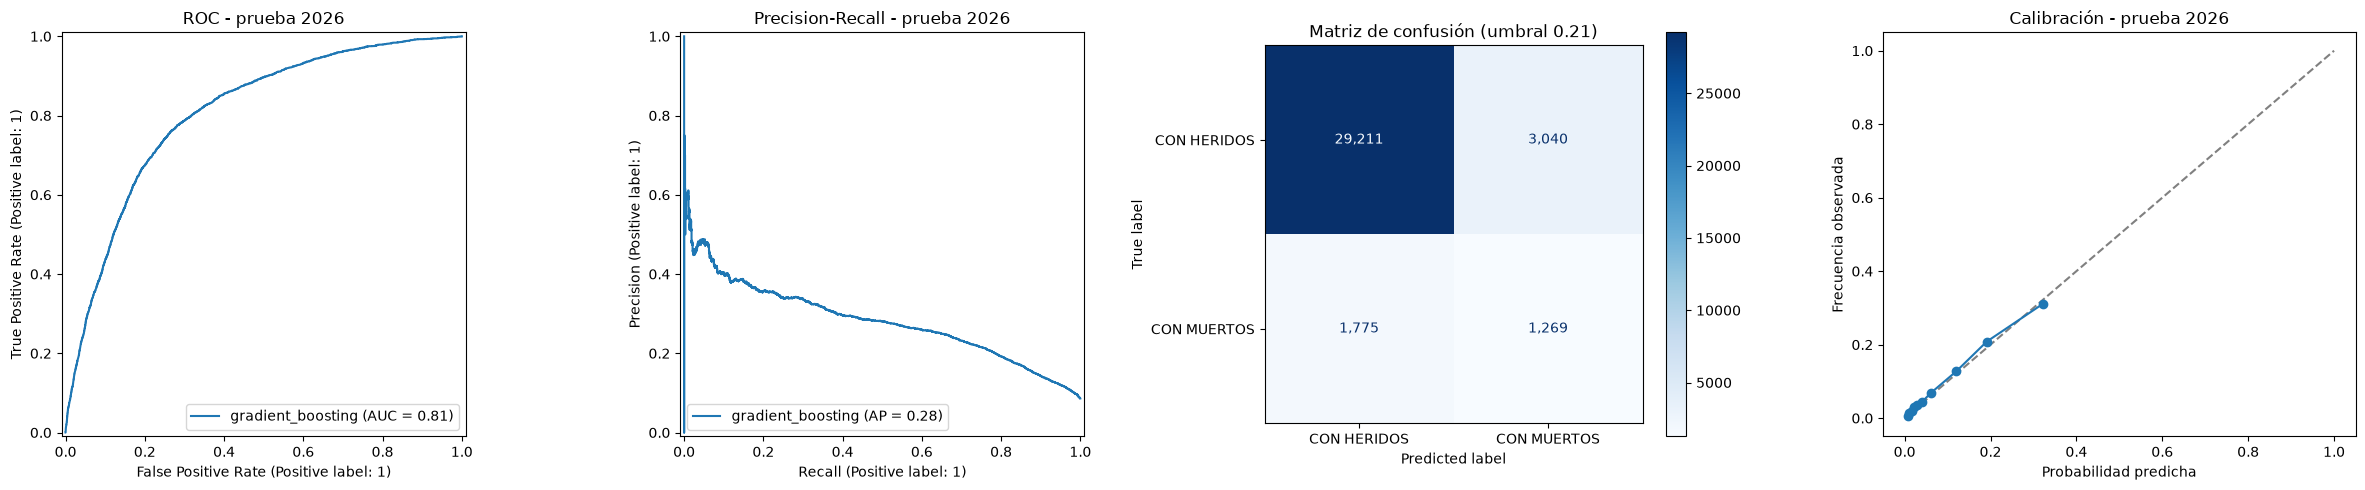

In [13]:
metricas_presentacion = metrics_df.copy().round(4)
display(metricas_presentacion)
display(model_config)
display(tuning_summary.round(4))
display(rolling_validation.round(4))
display(calibrated_metrics.round(4))
display(business_by_territory.head(20).round(4))

prob_true, prob_pred = calibration_curve(
    y_test,
    best_probability,
    n_bins=10,
    strategy="quantile",
)
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
RocCurveDisplay.from_predictions(y_test, best_probability, ax=axes[0], name=best_name)
axes[0].set_title("ROC - prueba 2026")
PrecisionRecallDisplay.from_predictions(y_test, best_probability, ax=axes[1], name=best_name)
axes[1].set_title("Precision-Recall - prueba 2026")
ConfusionMatrixDisplay.from_predictions(
    y_test, (best_probability >= best_threshold).astype(int),
    display_labels=["CON HERIDOS", "CON MUERTOS"], cmap="Blues", ax=axes[2], values_format=",d"
)
axes[2].set_title(f"Matriz de confusión (umbral {best_threshold:.2f})")
axes[3].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[3].plot(prob_pred, prob_true, marker="o")
axes[3].set_xlabel("Probabilidad predicha")
axes[3].set_ylabel("Frecuencia observada")
axes[3].set_title("Calibración - prueba 2026")
plt.tight_layout()
plt.show()


## Interpretación del benchmark y decisión de negocio

La comparación conserva una referencia lineal interpretable, un bosque aleatorio y un
gradient boosting de histogramas con target encoding. Los hiperparámetros se
seleccionan con validación temporal y un objetivo operacional, y la calibración
final se elige entre `sigmoid` e `isotonic` según el Brier de validación.
El ranking territorial usa tasas suavizadas, intervalos de Wilson y volumen mínimo:
sirve para priorizar revisión, no para afirmar que un territorio causa más siniestros.

Cuando exista un identificador oficial, el mismo notebook agregará vehículos al
accidente y recalculará métricas y ranking en esa unidad. Con el CSV actual, cualquier
conclusión debe llamarse tasa de registros de vehículos involucrados.


In [14]:
print("Modelo seleccionado:", best_name)
print("Método de calibración:", calibration_method)
print(f"Umbral operacional calibrado: {best_threshold:.3f}")
print(f"Capacidad máxima de alertas: {MAX_ALERT_RATE:.1%}")
print(f"Recall mínimo usado en tuning: {MIN_RECALL_FOR_TUNING:.1%}")
print(f"Costos FN/FP: {FALSE_NEGATIVE_COST:g}/{FALSE_POSITIVE_COST:g}")
print(f"Average Precision prueba 2026: {calibrated_test_metrics['average_precision']:.3f}")
print(f"Brier prueba 2026: {calibrated_test_metrics['brier']:.3f}")
print(f"Recall de CON MUERTOS: {calibrated_test_metrics['recall_muertes']:.3f}")
print(f"Precision de CON MUERTOS: {calibrated_test_metrics['precision_muertes']:.3f}")
print(f"Tasa de alertas: {calibrated_test_metrics['alert_rate']:.3%}")
print(f"Costo esperado normalizado: {calibrated_test_metrics['expected_cost']:.3f}")
print(f"Unidad de análisis: {summary['unidad_analisis']}")
print(f"ACCIDENTE_ID oficial disponible: {summary['identificador_accidente_disponible']}")
print("\nConfiguración seleccionada por familia:")
display(model_config)
print("\nPredicciones de prueba (muestra):")
display(test_result.head(10))
print("\nTop 10 territorios para priorización operativa:")
display(business_by_territory.loc[business_by_territory["volumen_suficiente"]].head(10).round(4))
if calibrated_test_metrics["alert_rate"] > MAX_ALERT_RATE:
    print(
        "Advertencia: la tasa de alertas en 2026 supera la capacidad de "
        "validación; revisar drift antes de operar el umbral."
    )


Modelo seleccionado: gradient_boosting
Método de calibración: sigmoid
Umbral operacional calibrado: 0.210
Capacidad máxima de alertas: 10.0%
Recall mínimo usado en tuning: 40.0%
Costos FN/FP: 5/1
Average Precision prueba 2026: 0.282
Brier prueba 2026: 0.069
Recall de CON MUERTOS: 0.417
Precision de CON MUERTOS: 0.294
Tasa de alertas: 12.209%
Costo esperado normalizado: 0.338
Unidad de análisis: registro de vehículo
ACCIDENTE_ID oficial disponible: False

Configuración seleccionada por familia:


,modelo,candidato_seleccionado,parametros
0,logistica_base,logistica_base_C2.0_peso5,"{'C': 2.0, 'class_weight': {0: 1, 1: 5}}"
1,logistica_interacciones,logistica_interacciones_C0.5_peso5,"{'C': 0.5, 'class_weight': {0: 1, 1: 5}}"
2,random_forest,random_forest_depth18_leaf20,"{'class_weight': 'balanced', 'max_depth': 18, ..."
3,gradient_boosting,gradient_boosting_lr0.06_hojas31_balanced,"{'class_weight': 'balanced', 'l2_regularizatio..."



Predicciones de prueba (muestra):


,MARCA_VEHICULO,TIPO_VEHICULO,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,GRAVEDAD_ACCIDENTE,probabilidad_muerte_calibrada,alerta
0,VOLKSWAGEN,CAMION,ANTIOQUIA,MEDELLIN,CON HERIDOS,0.120657,0
1,AKT,MOTOCICLETA,ANTIOQUIA,MEDELLIN,CON HERIDOS,0.075386,0
2,YAMAHA,MOTOCICLETA,ANTIOQUIA,GIRARDOTA,CON HERIDOS,0.068565,0
3,FOTON,TRACTOCAMION,ANTIOQUIA,GIRARDOTA,CON HERIDOS,0.109361,0
4,YAMAHA,MOTOCICLETA,SANTANDER,BUCARAMANGA,CON HERIDOS,0.036240,0
5,CHERY,CAMIONETA,SANTANDER,BUCARAMANGA,CON HERIDOS,0.017348,0
6,YAMAHA,MOTOCICLETA,ANTIOQUIA,COPACABANA,CON HERIDOS,0.116154,0
7,CHEVROLET,TRACTOCAMION,BOLIVAR,ACHI,CON MUERTOS,0.321431,1
8,VOLKSWAGEN,TRACTOCAMION,BOLIVAR,CLEMENCIA,CON HERIDOS,0.333237,1
9,BAJAJ,MOTOCICLETA,BOLIVAR,CLEMENCIA,CON HERIDOS,0.299772,1



Top 10 territorios para priorización operativa:


,DEPARTAMENTO_ACCIDENTE,MUNICIPIO_ACCIDENTE,unidades,muertes,tasa_observada,vehiculos_reportados,tasa_suavizada,tasa_ic95_inferior,tasa_ic95_superior,prioridad_score,volumen_suficiente,ranking_operativo
504,NARINO,TUMACO,323,218,0.6749,323,0.6387,0.6220,0.7237,3.6919,True,1.0
27,ANTIOQUIA,CAUCASIA,265,136,0.5132,265,0.4809,0.4533,0.5728,2.6852,True,2.0
278,CESAR,SAN DIEGO,437,168,0.3844,437,0.3699,0.3400,0.4309,2.2500,True,3.0
22,ANTIOQUIA,CACERES,82,47,0.5732,82,0.4712,0.4652,0.6746,2.0821,True,4.0
614,TOLIMA,ALVARADO,288,112,0.3889,288,0.3671,0.3344,0.4463,2.0800,True,5.0
103,ARAUCA,SARAVENA,114,57,0.5000,114,0.4333,0.4097,0.5903,2.0560,True,6.0
480,META,RESTREPO,660,212,0.3212,660,0.3133,0.2867,0.3578,2.0347,True,7.0
440,LA GUAJIRA,RIOHACHA,672,210,0.3125,672,0.3050,0.2786,0.3485,1.9861,True,8.0
599,SUCRE,SAMPUES,276,102,0.3696,276,0.3482,0.3148,0.4279,1.9582,True,9.0
418,HUILA,RIVERA,540,170,0.3148,540,0.3055,0.2771,0.3552,1.9224,True,10.0


Advertencia: la tasa de alertas en 2026 supera la capacidad de validación; revisar drift antes de operar el umbral.


## Clustering: perfiles territoriales y vehiculares

El clustering no usa `GRAVEDAD_ACCIDENTE` como entrada. Agrupa perfiles
`DEPARTAMENTO_ACCIDENTE × TIPO_VEHICULO` en la unidad de análisis efectiva y conserva
la gravedad únicamente para describir el resultado. Los tamaños pequeños se deben
revisar junto con el ranking territorial suavizado.


,k,silhouette,inertia,seleccionado
0,2,0.0984,6596.4219,False
1,3,0.1082,6179.4203,False
2,4,0.0978,5859.1933,False
3,5,0.3851,5703.4705,True
4,6,0.1699,5401.5761,False
5,7,0.0807,5182.4290,False
6,8,0.1133,4867.4951,False


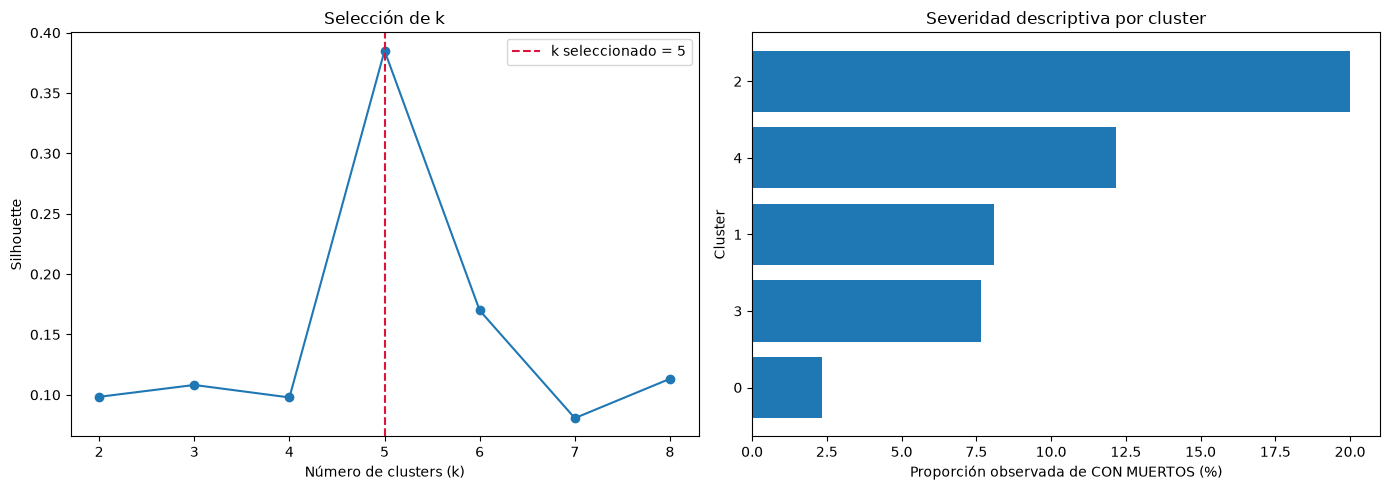

,cluster,perfiles,unidades,proporcion_muertes_ponderada,edad_mediana,tipos,departamentos
0,0,4,210007,0.0232,8.0,"MOTOCICLETA, AUTOMOVIL","ANTIOQUIA, BOGOTA D.C., VALLE DEL CAUCA"
1,1,135,139417,0.0809,9.0,"CAMIONETA, MOTOCICLETA, MOTOCARRO","VALLE DEL CAUCA, ATLANTICO, ANTIOQUIA, ARCHIPI..."
2,2,9,10,0.2000,6.0,"MINICARGADOR, TRACTOR, FRESADORA","CUNDINAMARCA, VICHADA, ATLANTICO, CALDAS, HUILA"
3,3,213,100720,0.0766,15.0,"VOLQUETA, CAMION, CAMPERO","ANTIOQUIA, CALDAS, CAUCA, VALLE DEL CAUCA, CAQ..."
4,4,26,181,0.1215,6.0,"MOTOCARRO, CICLOMOTOR, CUADRICICLO","ARAUCA, ANTIOQUIA, ARCHIPIELAGO DE SAN ANDRES,..."


In [15]:
display(cluster_metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(cluster_metrics["k"], cluster_metrics["silhouette"], marker="o")
axes[0].axvline(chosen_k, color="crimson", linestyle="--", label=f"k seleccionado = {chosen_k}")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Silhouette")
axes[0].set_title("Selección de k")
axes[0].legend()
plot_profile = cluster_profile.sort_values("proporcion_muertes_ponderada")
axes[1].barh(plot_profile["cluster"].astype(str), plot_profile["proporcion_muertes_ponderada"] * 100)
axes[1].set_xlabel("Proporción observada de CON MUERTOS (%)")
axes[1].set_ylabel("Cluster")
axes[1].set_title("Severidad descriptiva por cluster")
plt.tight_layout()
plt.show()

display(cluster_profile.round(4))


## Lectura para una Secretaría de Tránsito

- La fuente actual no incluye un ID oficial de accidente; `ACCIDENTE_ID` queda
  implementado con trazabilidad y marca de origen. El surrogate no agrupa vehículos.
- El modelo prioriza **unidades ya reportadas** según la gravedad observada; no predice
  dónde ocurrirá un accidente ni reemplaza la investigación.
- Cuando llegue un ID oficial, el notebook agrega vehículos por accidente, evita fuga
  entre particiones y recalcula todo a nivel siniestro.
- La selección del modelo combina validación temporal, recall mínimo, costo esperado,
  tasa de alertas y calibración.
- El ranking territorial usa volumen, tasa suavizada e intervalo de confianza para
  evitar decisiones basadas en municipios pequeños con pocos casos.
- Las tasas son descriptivas y no causales. Para medir riesgo preventivo aún se necesita
  exposición: tráfico, población, parque automotor o kilómetros recorridos.
- Se recomienda usar el ranking como lista de revisión y complementar con inspección
  de vías, condiciones operativas y calidad de reporte.


## Exportación de artefactos

La carpeta `artifacts/` guarda todo lo que la aplicación Streamlit (`main.py`) necesita
para mostrar resultados sin reentrenar: métricas, curvas, ranking territorial,
clusters, predicciones de prueba, el modelo calibrado y las opciones del simulador.
Así los números del tablero son exactamente los del notebook y la app puede
desplegarse en producción con solo este repositorio.

In [16]:
ARTIFACTS = BASE / "artifacts"
ARTIFACTS.mkdir(exist_ok=True)

# --- Tablas del benchmark y la calibración -----------------------------------
metrics_df.to_csv(ARTIFACTS / "metricas_benchmark.csv", index=False)
model_config.to_csv(ARTIFACTS / "configuracion_modelos.csv", index=False)
tuning_summary.to_csv(ARTIFACTS / "tuning_resumen.csv", index=False)
rolling_validation.to_csv(ARTIFACTS / "validacion_rolling.csv", index=False)
calibrated_metrics.to_csv(ARTIFACTS / "metricas_calibradas.csv", index=False)
calibration_comparison.to_csv(ARTIFACTS / "calibracion_candidatos.csv", index=False)
calibrated_thresholds.to_csv(ARTIFACTS / "tabla_umbrales.csv", index=False)

# --- Curvas del modelo final en la prueba 2026 -------------------------------
fpr, tpr, _ = roc_curve(y_test, best_probability)
pd.DataFrame({"fpr": fpr, "tpr": tpr}).to_csv(
    ARTIFACTS / "curva_roc.csv", index=False
)
pr_precision, pr_recall, _ = precision_recall_curve(y_test, best_probability)
pr_points = pd.DataFrame({"recall": pr_recall, "precision": pr_precision})
step = max(1, len(pr_points) // 2000)  # la curva completa no aporta más detalle visual
pr_points.iloc[::step].to_csv(ARTIFACTS / "curva_pr.csv", index=False)
pd.DataFrame({
    "probabilidad_predicha": prob_pred,
    "frecuencia_observada": prob_true,
}).to_csv(ARTIFACTS / "curva_calibracion.csv", index=False)

# --- Territorio, clustering y predicciones -----------------------------------
business_by_territory.to_csv(ARTIFACTS / "ranking_territorial.csv", index=False)
cluster_profile.to_csv(ARTIFACTS / "perfiles_cluster.csv", index=False)
cluster_metrics.to_csv(ARTIFACTS / "metricas_cluster.csv", index=False)
profile[
    ["DEPARTAMENTO_ACCIDENTE", "TIPO_VEHICULO", "unidades",
     "edad_mediana", "tasa_muertes", "cluster"]
].to_csv(ARTIFACTS / "perfil_detalle_cluster.csv", index=False)
test_result.to_csv(ARTIFACTS / "predicciones_test_2026.csv", index=False)

# --- Agregados de EDA (la app no carga el CSV de 450k filas) ------------------
df.groupby("GRAVEDAD_ACCIDENTE", as_index=False).agg(
    registros=("y", "size")
).to_csv(ARTIFACTS / "eda_gravedad.csv", index=False)
for column, filename, top_n in (
    ("TIPO_VEHICULO", "eda_tipo_vehiculo.csv", 15),
    ("DEPARTAMENTO_ACCIDENTE", "eda_departamento.csv", 15),
    ("MARCA_VEHICULO", "eda_marca.csv", 15),
):
    (
        df.groupby(column, as_index=False)
        .agg(registros=("y", "size"), tasa_muertes=("y", "mean"))
        .sort_values("registros", ascending=False)
        .head(top_n)
        .to_csv(ARTIFACTS / filename, index=False)
    )
df.groupby(["ANIO_ACCIDENTE", "GRAVEDAD_ACCIDENTE"], as_index=False).agg(
    registros=("y", "size")
).to_csv(ARTIFACTS / "eda_anio_gravedad.csv", index=False)
df.groupby("MES_ACCIDENTE", as_index=False).agg(
    registros=("y", "size"), tasa_muertes=("y", "mean")
).to_csv(ARTIFACTS / "eda_mes.csv", index=False)

# --- Modelo calibrado y opciones del simulador --------------------------------
joblib.dump(
    {
        "model": calibrated_model,
        "threshold": float(best_threshold),
        "categorical": categorical,
        "numeric": numeric,
        "best_name": best_name,
        "calibration_method": calibration_method,
    },
    ARTIFACTS / "modelo_final.joblib",
)

simulator_options = {
    "marcas": sorted(train["MARCA_VEHICULO"].dropna().unique().tolist()),
    "tipos_vehiculo": sorted(train["TIPO_VEHICULO"].dropna().unique().tolist()),
    "autoridades": sorted(train["AUTORIDAD_DE_TRANSITO"].dropna().unique().tolist()),
    "municipios_por_departamento": {
        depto: sorted(group["MUNICIPIO_ACCIDENTE"].dropna().unique().tolist())
        for depto, group in train.groupby("DEPARTAMENTO_ACCIDENTE")
    },
    "anio_prueba": 2026,
    "modelo_vehiculo_min": 1950,
    "modelo_vehiculo_max": 2027,
}
with (ARTIFACTS / "opciones_simulador.json").open("w", encoding="utf-8") as f:
    json.dump(simulator_options, f, ensure_ascii=False)

resumen_export = {
    **summary,
    "mejor_candidato_por_familia": model_config.to_dict(orient="records"),
    "metricas_test_2026": {
        k: float(v) for k, v in calibrated_test_metrics.items()
    },
    "metricas_valid_2025": {
        k: float(v) for k, v in calibrated_valid_metrics.items()
    },
    "costo_falso_negativo": FALSE_NEGATIVE_COST,
    "costo_falso_positivo": FALSE_POSITIVE_COST,
    "pesos_clase_modelo_final": class_weight_choice,
    "calibracion_candidato": chosen_calibration,
}
with (ARTIFACTS / "resumen.json").open("w", encoding="utf-8") as f:
    json.dump(resumen_export, f, ensure_ascii=False, indent=2, default=float)

print(f"Artefactos exportados en: {ARTIFACTS.resolve()}")
for path in sorted(ARTIFACTS.iterdir()):
    print(f"  {path.name} ({path.stat().st_size / 1024:.0f} KB)")


Artefactos exportados en: C:\Semestre 2026-2\IA\final-project-ai-intro\artifacts
  calibracion_candidatos.csv (1 KB)
  colombia_departamentos.geojson (376 KB)
  configuracion_modelos.csv (1 KB)
  curva_calibracion.csv (0 KB)
  curva_pr.csv (78 KB)
  curva_roc.csv (407 KB)
  eda_anio_gravedad.csv (0 KB)
  eda_departamento.csv (1 KB)
  eda_gravedad.csv (0 KB)
  eda_marca.csv (1 KB)
  eda_mes.csv (0 KB)
  eda_tipo_vehiculo.csv (0 KB)
  metricas_benchmark.csv (2 KB)
  metricas_calibradas.csv (1 KB)
  metricas_cluster.csv (0 KB)
  modelo_final.joblib (501 KB)
  opciones_simulador.json (21 KB)
  perfil_detalle_cluster.csv (17 KB)
  perfiles_cluster.csv (1 KB)
  predicciones_test_2026.csv (2490 KB)
  ranking_territorial.csv (84 KB)
  resumen.json (3 KB)
  tabla_umbrales.csv (47 KB)
  tuning_resumen.csv (6 KB)
  validacion_rolling.csv (3 KB)
